# Etapa 3 — Preparação dos Dados para Modelagem (WineQT)

**Objetivo:** preparar a base WineQT de forma **reproduzível** e **sem vazamento de dados**, para que os modelos de classificação sejam desenvolvidos e treinados na Etapa 4.

**Entrada (vinda da EDA):** estrutura da base, distribuição das notas, correlações, desbalanceamento de classes e possíveis outliers (IQR).
**Saída (para a Etapa 4):** `X_train`, `X_test`, `y_train`, `y_test` (originais e padronizados), o padronizador ajustado apenas no treino e o registro das decisões — tudo na pasta `dados_preparados/`.

| Seção | Conteúdo |
|---|---|
| 1 | Revisão dos achados da EDA e estrutura dos dados |
| 2 | Definição da variável alvo `quality_class` |
| 3 | Ausentes, duplicatas e inconsistências |
| 4 | Verificação da coluna `Id` |
| 5 | Separação de `X` e `y` |
| 6 | Divisão treino/teste estratificada |
| 7 | Outliers (sinalizados, não removidos) |
| 8 | Transformações sem vazamento (padronização) |
| 9 | Avaliação de feature engineering |
| 10 | Desbalanceamento: estratégia para a Etapa 4 |
| 11 | Exportação dos artefatos |
| 12 | Registro de decisões e passagem de trabalho |

> Requisitos: `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `joblib`.
> Se faltar algo no ambiente: `pip install scikit-learn joblib`.

In [46]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import joblib

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Ambiente funcionando!")

Python: c:\Users\Joey Usagii\.venv\Scripts\python.exe
Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1
Ambiente funcionando!


In [47]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---------------- Parâmetros fixos (reprodutibilidade) ----------------
RANDOM_STATE = 42          # semente única usada em toda a etapa
TEST_SIZE    = 0.20        # 20% das amostras reservadas para teste
LIMIAR_ALTA  = 7           # quality >= 7 -> alta qualidade
#CAMINHO_DADOS = Path("WineQT.csv")
#PASTA_SAIDA   = Path("dados_preparados")
# ---------------- Caminhos do projeto ----------------

RAIZ_PROJETO = Path.cwd()

# Compatibilidade com execução pela raiz ou pela pasta Etapa3
if (RAIZ_PROJETO / "Etapa3").exists():
    PASTA_ETAPA3 = RAIZ_PROJETO / "Etapa3"
elif RAIZ_PROJETO.name == "Etapa3":
    PASTA_ETAPA3 = RAIZ_PROJETO
else:
    raise FileNotFoundError(
        "Não foi possível localizar a pasta Etapa3."
    )

CAMINHO_DADOS = (
    PASTA_ETAPA3.parent
    / "Challeng 2"
    / "vinho-tech-challenge"
    / "WineQT.csv"
)

PASTA_SAIDA = PASTA_ETAPA3 / "dados_preparados"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

if not CAMINHO_DADOS.exists():
    raise FileNotFoundError(
        f"Base WineQT não encontrada: {CAMINHO_DADOS}"
    )

print("Base de entrada:", CAMINHO_DADOS)
print("Pasta de saída:", PASTA_SAIDA)


#PASTA_SAIDA.mkdir(exist_ok=True)

pd.set_option("display.float_format", "{:.4f}".format)
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Base de entrada: c:\Users\Joey Usagii\Documents\GitHub\Tech-Challeng\Challeng 2\vinho-tech-challenge\WineQT.csv
Pasta de saída: c:\Users\Joey Usagii\Documents\GitHub\Tech-Challeng\Etapa3\dados_preparados
pandas 3.1.0 | scikit-learn 1.9.1


## 1. Revisão dos achados da EDA e estrutura dos dados

Resumo do que a EDA (Etapa 2) entregou:

| Tema | Achado da EDA | O que a preparação faz com isso |
|---|---|---|
| Estrutura | 1.143 linhas, 13 colunas (11 físico-químicas + `quality` + `Id`) | Confirmar tipos e formato |
| Ausentes / duplicatas | 0 ausentes, 0 duplicatas (contadas **com** a coluna `Id`) | Reconferir **sem** o `Id` (ver seção 3) |
| Classes | Alta (≥7): 13,9% · Baixa/média (<7): 86,1% | Divisão estratificada e estratégia para desbalanceamento |
| Correlações | `alcohol` (+0,49) e `volatile acidity` (−0,41) são as mais fortes | Mantidas como preditoras; nenhuma variável descartada |
| Outliers (IQR) | Maiores taxas em `residual sugar` (9,6%) e `chlorides` (6,7%) | Manter registros; não remover automaticamente |

In [48]:
df_original = pd.read_csv(CAMINHO_DADOS)
df = df_original.copy()

print("Formato:", df.shape)
print("\nTipos de dados:")
print(df.dtypes.to_string())
display(df.head())

Formato: (1143, 13)

Tipos de dados:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,0
1,7.8000,0.8800,0.0000,2.6000,0.0980,25.0000,67.0000,0.9968,3.2000,0.6800,9.8000,5,1
2,7.8000,0.7600,0.0400,2.3000,0.0920,15.0000,54.0000,0.9970,3.2600,0.6500,9.8000,5,2
3,11.2000,0.2800,0.5600,1.9000,0.0750,17.0000,60.0000,0.9980,3.1600,0.5800,9.8000,6,3
4,7.4000,0.7000,0.0000,1.9000,0.0760,11.0000,34.0000,0.9978,3.5100,0.5600,9.4000,5,4


In [49]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0000,8.3111,1.7476,4.6000,7.1000,7.9000,9.1000,15.9000
volatile acidity,1143.0000,0.5313,0.1796,0.1200,0.3925,0.5200,0.6400,1.5800
citric acid,1143.0000,0.2684,0.1967,0.0000,0.0900,0.2500,0.4200,1.0000
residual sugar,1143.0000,2.5322,1.3559,0.9000,1.9000,2.2000,2.6000,15.5000
chlorides,1143.0000,0.0869,0.0473,0.0120,0.0700,0.0790,0.0900,0.6110
free sulfur dioxide,1143.0000,15.6155,10.2505,1.0000,7.0000,13.0000,21.0000,68.0000
total sulfur dioxide,1143.0000,45.9147,32.7821,6.0000,21.0000,37.0000,61.0000,289.0000
density,1143.0000,0.9967,0.0019,0.9901,0.9956,0.9967,0.9978,1.0037
pH,1143.0000,3.3110,0.1567,2.7400,3.2050,3.3100,3.4000,4.0100
sulphates,1143.0000,0.6577,0.1704,0.3300,0.5500,0.6200,0.7300,2.0000


Todas as colunas são numéricas (`float64` para as medições, `int64` para `quality` e `Id`). Não há variáveis categóricas, portanto **não é necessário encoding**.

## 2. Definição da variável alvo

Conforme o enunciado, a nota `quality` é transformada em classificação binária:

- `quality_class = 1` → **alta qualidade** (`quality ≥ 7`)
- `quality_class = 0` → **baixa/média qualidade** (`quality < 7`)

A coluna `quality` original **não** será usada como preditora: ela é a própria origem do alvo e usá-la seria vazamento direto.

In [50]:
df["quality_class"] = (df["quality"] >= LIMIAR_ALTA).astype(int)

# Conferência da regra: cada nota deve cair em exatamente uma classe
display(pd.crosstab(df["quality"], df["quality_class"], margins=True, margins_name="Total"))

dist = (df["quality_class"].value_counts().rename("quantidade").to_frame()
        .assign(percentual=lambda t: t["quantidade"] / t["quantidade"].sum() * 100))
display(dist)

quality_class,0,1,Total
quality,,,
3,6,0,6
4,33,0,33
5,483,0,483
6,462,0,462
7,0,143,143
8,0,16,16
Total,984,159,1143


,quantidade,percentual
quality_class,,
0,984,86.0892
1,159,13.9108


## 3. Valores ausentes, duplicatas e inconsistências

A EDA contou duplicatas considerando todas as colunas, **inclusive o `Id`**. Como o `Id` é diferente em toda linha, essa contagem nunca encontraria repetições. Aqui a verificação é refeita **ignorando o `Id`**, que é o que importa para o modelo.

In [51]:
colunas_fisico_quimicas = [c for c in df_original.columns if c not in ("Id", "quality")]

# 3.1 Ausentes
print("Valores ausentes por coluna:")
print(df.isna().sum().to_string())

# 3.2 Duplicatas
dup_com_id = df.duplicated().sum()
dup_sem_id = df.duplicated(subset=colunas_fisico_quimicas + ["quality"]).sum()
dup_so_features = df.duplicated(subset=colunas_fisico_quimicas).sum()

print(f"\nDuplicatas considerando o Id ................. {dup_com_id}")
print(f"Duplicatas ignorando o Id (medições + nota) .. {dup_sem_id}")
print(f"Duplicatas só nas medições físico-químicas ... {dup_so_features}")

Valores ausentes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
quality_class           0

Duplicatas considerando o Id ................. 0
Duplicatas ignorando o Id (medições + nota) .. 125
Duplicatas só nas medições físico-químicas ... 125


In [52]:
# Duplicatas com mesmas medições mas notas diferentes seriam rótulos conflitantes
conflitos = (df.groupby(colunas_fisico_quimicas)["quality"].nunique() > 1).sum()
print("Grupos de medições idênticas com notas diferentes:", conflitos)

linhas_envolvidas = df.duplicated(subset=colunas_fisico_quimicas, keep=False).sum()
print("Linhas envolvidas em algum grupo duplicado:", linhas_envolvidas)
print("Cópias excedentes (a remover):", dup_sem_id)
print("Cópias excedentes de vinhos de alta qualidade:",
      int(df[df.duplicated(subset=colunas_fisico_quimicas)]["quality_class"].sum()))

Grupos de medições idênticas com notas diferentes: 0
Linhas envolvidas em algum grupo duplicado: 239
Cópias excedentes (a remover): 125
Cópias excedentes de vinhos de alta qualidade: 22


In [53]:
# 3.3 Inconsistências de domínio (regras físico-químicas)
checagens = {
    "valores negativos em medições": int((df[colunas_fisico_quimicas] < 0).sum().sum()),
    "SO2 livre > SO2 total": int((df["free sulfur dioxide"] > df["total sulfur dioxide"]).sum()),
    "pH fora de [0, 14]": int((~df["pH"].between(0, 14)).sum()),
    "densidade fora de [0,98, 1,05] g/cm³": int((~df["density"].between(0.98, 1.05)).sum()),
    "álcool fora de [5, 20] %": int((~df["alcohol"].between(5, 20)).sum()),
    "quality fora de [0, 10]": int((~df["quality"].between(0, 10)).sum()),
}
display(pd.Series(checagens, name="ocorrências").to_frame())

,ocorrências
valores negativos em medições,0
SO2 livre > SO2 total,0
"pH fora de [0, 14]",0
"densidade fora de [0,98, 1,05] g/cm³",0
"álcool fora de [5, 20] %",0
"quality fora de [0, 10]",0


**Decisões desta seção**

- **Ausentes:** nenhum → nenhuma imputação necessária.
- **Inconsistências de domínio:** nenhuma → nenhum valor corrigido.
- **Duplicatas (ignorando o `Id`): 125 cópias excedentes → removidas, mantendo a primeira ocorrência.**
  - Todas as cópias têm a mesma nota (não há rótulos conflitantes), então são repetições exatas da mesma amostra, sem informação nova.
  - Se mantidas, a divisão aleatória poderia colocar uma cópia no treino e outra no teste. O modelo seria avaliado em amostras que já “viu”, **inflando as métricas** — um vazamento de dados.
  - O impacto no balanceamento é pequeno (ver abaixo): a proporção de alta qualidade passa de 13,9% para cerca de 13,5%.

In [54]:
n_antes = len(df)
prop_antes = df["quality_class"].mean() * 100

df = (df.drop_duplicates(subset=colunas_fisico_quimicas + ["quality"], keep="first")
        .reset_index(drop=True))

print(f"Linhas: {n_antes} -> {len(df)} (removidas {n_antes - len(df)})")
print(f"% alta qualidade: {prop_antes:.2f}% -> {df['quality_class'].mean() * 100:.2f}%")

Linhas: 1143 -> 1018 (removidas 125)
% alta qualidade: 13.91% -> 13.46%


## 4. Verificação da coluna `Id`

Antes de excluir, confirmamos que `Id` é apenas um identificador de linha e não carrega informação sobre o vinho.

In [55]:
print("Id único por linha:", df["Id"].is_unique)
print("Id em ordem crescente:", df["Id"].is_monotonic_increasing)
print(f"Faixa: {df['Id'].min()} a {df['Id'].max()} (com lacunas: {df['Id'].max() + 1 - df_original.shape[0]} valores ausentes na sequência original)")
print(f"Correlação Id x quality: {df['Id'].corr(df['quality']):.3f}")

Id único por linha: True
Id em ordem crescente: True
Faixa: 0 a 1597 (com lacunas: 455 valores ausentes na sequência original)
Correlação Id x quality: 0.079


**Decisão:** `Id` é **excluído das variáveis preditoras**.

- É único, sequencial e só indica a posição do registro no arquivo (a sequência vai até 1597 com lacunas, ou seja, é a numeração de uma base maior da qual o WineQT é um recorte).
- Não é uma medição físico-química, então não teria significado para enólogos nem estaria disponível de forma útil para um vinho novo.
- A correlação fraca com `quality` (≈0,08) reflete a ordem em que as amostras foram registradas, não uma característica do vinho. Usá-lo poderia fazer o modelo aprender um artefato do arquivo.

O `Id` é guardado à parte (`ids_train` / `ids_test`) apenas para rastreabilidade.

## 5. Separação de `X` (preditoras) e `y` (alvo)

In [56]:
COLUNAS_EXCLUIDAS = ["Id", "quality", "quality_class"]
FEATURES = colunas_fisico_quimicas            # as 11 medições físico-químicas
ALVO = "quality_class"

X = df[FEATURES].copy()
y = df[ALVO].copy()
ids = df["Id"].copy()

print("X:", X.shape, "| y:", y.shape)
print("Preditoras:", FEATURES)
assert not set(COLUNAS_EXCLUIDAS) & set(X.columns), "Coluna proibida em X!"

X: (1018, 11) | y: (1018,)
Preditoras: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


## 6. Divisão treino/teste reproduzível e estratificada

- **80% treino / 20% teste**, com `random_state=42` para que qualquer pessoa obtenha exatamente a mesma divisão.
- **`stratify=y`**: como só ~13,5% das amostras são de alta qualidade, uma divisão puramente aleatória poderia deixar o teste com poucos exemplos dessa classe. A estratificação preserva a proporção nos dois conjuntos.
- A divisão é feita **antes** de qualquer transformação: a partir daqui, o conjunto de teste fica isolado.

In [57]:
X_train, X_test, y_train, y_test, ids_train, ids_test = train_test_split(
    X, y, ids,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

resumo_split = pd.DataFrame({
    "amostras": [len(y), len(y_train), len(y_test)],
    "alta qualidade (1)": [y.sum(), y_train.sum(), y_test.sum()],
    "% alta qualidade": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["base completa", "treino", "teste"])
display(resumo_split)

# Verificação de vazamento: nenhuma amostra idêntica em treino e teste
sobreposicao = pd.merge(X_train, X_test, how="inner", on=FEATURES)
print("Amostras idênticas entre treino e teste:", len(sobreposicao))
assert len(sobreposicao) == 0

,amostras,alta qualidade (1),% alta qualidade
base completa,1018,137,13.4578
treino,814,110,13.5135
teste,204,27,13.2353


Amostras idênticas entre treino e teste: 0


## 7. Outliers: sinalizados, não removidos

A EDA usou o IQR para sinalizar possíveis outliers. Aqui os limites são recalculados **somente com o treino**, para registrar a situação sem usar informação do teste.

**Decisão: nenhum outlier é removido ou truncado.**
- Os valores passaram nas checagens de domínio da seção 3 (são fisicamente plausíveis).
- Em vinhos, valores altos de açúcar residual, cloretos ou sulfatos podem ser estilos legítimos de produção, e vinhos de alta qualidade podem justamente estar nas pontas (ex.: teor alcoólico alto).
- Remover linhas só no treino mudaria a distribuição em relação ao teste e a vinhos reais.
- O IQR por coluna é univariado e apenas sinaliza casos para investigação, como já registrado na EDA.

In [58]:
q1, q3 = X_train.quantile(0.25), X_train.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr

fora = (X_train.lt(lim_inf) | X_train.gt(lim_sup))
outliers_treino = pd.DataFrame({
    "qtd_treino": fora.sum(),
    "%_treino": fora.mean() * 100,
    "% entre os sinalizados que são alta qualidade": [
        y_train[fora[c]].mean() * 100 if fora[c].any() else np.nan for c in FEATURES
    ],
}).sort_values("qtd_treino", ascending=False)
display(outliers_treino)
print(f"Amostras de treino com pelo menos 1 sinalização: {fora.any(axis=1).sum()} "
      f"({fora.any(axis=1).mean() * 100:.1f}%)")

,qtd_treino,%_treino,% entre os sinalizados que são alta qualidade
residual sugar,66,8.1081,25.7576
chlorides,52,6.3882,7.6923
sulphates,35,4.2998,17.1429
fixed acidity,28,3.4398,25.0000
total sulfur dioxide,28,3.4398,7.1429
density,25,3.0713,36.0000
pH,16,1.9656,25.0000
free sulfur dioxide,9,1.1057,11.1111
volatile acidity,8,0.9828,0.0000
alcohol,5,0.6143,40.0000


Amostras de treino com pelo menos 1 sinalização: 197 (24.2%)


Cerca de 24% das amostras de treino têm pelo menos uma sinalização: excluí-las descartaria um quarto de um conjunto já pequeno. Além disso, entre os sinalizados em `density`, `residual sugar`, `fixed acidity` e `pH`, a proporção de vinhos de alta qualidade (25–36%) é **maior** que a média do treino (~13,5%). Ou seja, os extremos carregam informação justamente sobre a classe minoritária — mais um motivo para mantê-los.

## 8. Transformações sem vazamento de dados

### 8.1 Quais modelos precisam de padronização?

As variáveis estão em escalas muito diferentes (ex.: `density` ≈ 0,99 com variação na 3ª casa decimal; `total sulfur dioxide` vai até ~290). O efeito disso depende do modelo:

| Família de modelo | Precisa de escala? | Por quê |
|---|---|---|
| Regressão Logística | **Sim** | A regularização penaliza os coeficientes por igual; sem escala, variáveis com números grandes seriam tratadas de forma injusta. A otimização também converge melhor. |
| KNN | **Sim** | Usa distâncias; a variável de maior escala dominaria o cálculo. |
| SVM | **Sim** | Kernel e margem dependem de distâncias. |
| Árvore de Decisão, Random Forest, Gradient Boosting | **Não** | Dividem os dados por limiares em cada variável; a ordem dos valores não muda com a escala. |

Por isso a Etapa 4 recebe **duas versões** dos dados: a original (para modelos de árvore) e a padronizada (para modelos baseados em distância ou coeficientes).

In [59]:
escalas = pd.DataFrame({"mínimo": X_train.min(), "máximo": X_train.max(),
                        "desvio padrão": X_train.std(), "assimetria (skew)": X_train.skew()})
display(escalas.sort_values("desvio padrão", ascending=False))

,mínimo,máximo,desvio padrão,assimetria (skew)
total sulfur dioxide,6.0000,289.0000,33.8238,1.7706
free sulfur dioxide,1.0000,68.0000,10.1282,1.1276
fixed acidity,4.9000,15.6000,1.7407,0.9870
residual sugar,0.9000,15.4000,1.1926,4.1693
alcohol,8.4000,14.0000,1.0803,0.8180
citric acid,0.0000,1.0000,0.1979,0.3168
volatile acidity,0.1200,1.5800,0.1853,0.7870
sulphates,0.3300,2.0000,0.1752,2.4871
pH,2.7400,4.0100,0.1601,0.2129
chlorides,0.0120,0.6110,0.0518,5.6782


### 8.2 Escolha do método: `StandardScaler`

- **Padronização (`StandardScaler`, média 0 e desvio 1)** foi escolhida em vez de normalização Min-Max: o Min-Max usa o mínimo e o máximo, que são justamente os pontos extremos que decidimos manter — um único outlier comprimiria todo o resto da variável numa faixa estreita.
- **Ajuste somente no treino:** a média e o desvio padrão são calculados com `X_train` (`fit`) e aplicados, já fixos, a treino e teste (`transform`). O teste nunca é usado para ajustar nada.
- **Assimetria:** `chlorides`, `residual sugar` e `sulphates` têm cauda longa à direita. Uma transformação logarítmica **não** é aplicada nesta etapa porque não há evidência de que seja necessária; fica registrada como possível teste na Etapa 4 caso a Regressão Logística apresente desempenho fraco.

In [60]:
scaler = StandardScaler()
scaler.fit(X_train)                      # aprende média e desvio APENAS do treino

X_train_scaled = pd.DataFrame(scaler.transform(X_train), columns=FEATURES, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),  columns=FEATURES, index=X_test.index)

parametros_scaler = pd.DataFrame({"média (treino)": scaler.mean_,
                                  "desvio (treino)": scaler.scale_}, index=FEATURES)
display(parametros_scaler)

,média (treino),desvio (treino)
fixed acidity,8.3269,1.7396
volatile acidity,0.5315,0.1852
citric acid,0.2750,0.1978
residual sugar,2.4699,1.1919
chlorides,0.0885,0.0518
free sulfur dioxide,15.5627,10.1220
total sulfur dioxide,46.1744,33.8030
density,0.9967,0.0019
pH,3.3097,0.1600
sulphates,0.6628,0.1751


In [61]:
# Conferência: no treino a média fica ~0 e o desvio ~1 por construção.
# No teste os valores ficam próximos, mas NÃO exatamente 0 e 1 — sinal de que o teste não foi usado no ajuste.
conferencia = pd.DataFrame({
    "média treino": X_train_scaled.mean(), "desvio treino": X_train_scaled.std(ddof=0),
    "média teste": X_test_scaled.mean(),   "desvio teste": X_test_scaled.std(ddof=0),
})
display(conferencia)
assert np.allclose(X_train_scaled.mean(), 0, atol=1e-9)

,média treino,desvio treino,média teste,desvio teste
fixed acidity,-0.0000,1.0000,-0.1101,0.9976
volatile acidity,0.0000,1.0000,0.0544,0.9407
citric acid,0.0000,1.0000,-0.1576,0.9469
residual sugar,0.0000,1.0000,0.2282,1.4267
chlorides,0.0000,1.0000,-0.1238,0.6049
free sulfur dioxide,0.0000,1.0000,0.0425,1.0235
total sulfur dioxide,0.0000,1.0000,0.0223,0.8923
density,-0.0000,1.0000,-0.0339,1.0167
pH,0.0000,1.0000,0.0561,0.9242
sulphates,0.0000,1.0000,-0.1716,0.7426


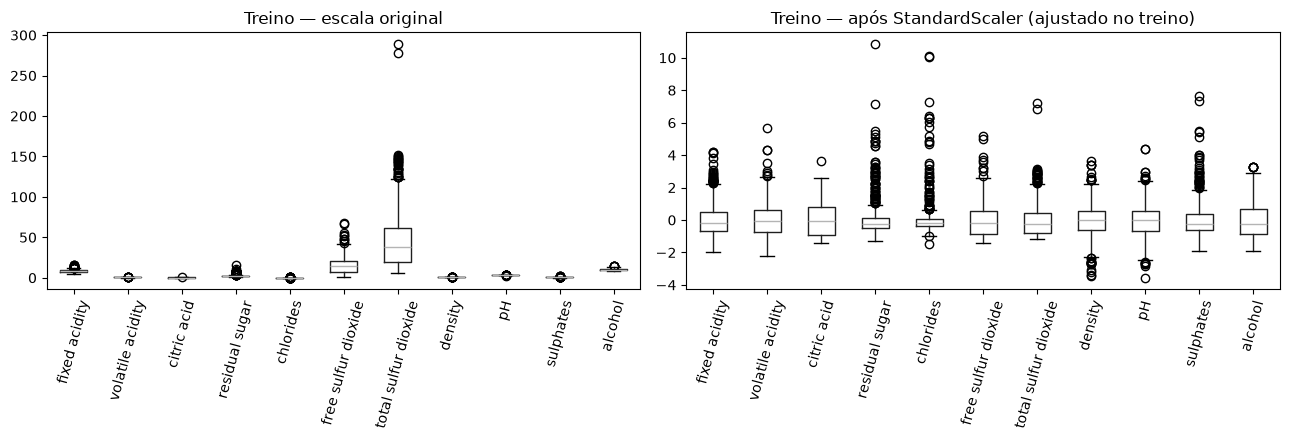

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
X_train.boxplot(ax=axes[0], rot=75, grid=False)
axes[0].set_title("Treino — escala original")
X_train_scaled.boxplot(ax=axes[1], rot=75, grid=False)
axes[1].set_title("Treino — após StandardScaler (ajustado no treino)")
plt.tight_layout()
plt.savefig(PASTA_SAIDA / "antes_depois_padronizacao.png", dpi=120)
plt.show()

## 9. Feature engineering: é realmente necessário?

Foram avaliadas três variáveis candidatas com significado químico. A análise usa **somente o treino**.

| Candidata | Fórmula | Ideia |
|---|---|---|
| `total_acidity` | fixed + volatile + citric | acidez total do vinho |
| `bound_so2` | total SO2 − free SO2 | SO2 combinado |
| `so2_ratio` | free SO2 / total SO2 | fração de SO2 ativo (proteção antimicrobiana) |

Critério: a nova variável só entra se trouxer associação com o alvo **e** não for redundante com uma variável já existente.

In [63]:
cand = pd.DataFrame(index=X_train.index)
cand["total_acidity"] = X_train["fixed acidity"] + X_train["volatile acidity"] + X_train["citric acid"]
cand["bound_so2"]     = X_train["total sulfur dioxide"] - X_train["free sulfur dioxide"]
cand["so2_ratio"]     = X_train["free sulfur dioxide"] / X_train["total sulfur dioxide"]

avaliacao = pd.DataFrame({
    "corr. com alvo (treino)": cand.corrwith(y_train),
    "variável original mais parecida": [X_train.corrwith(cand[c]).abs().idxmax() for c in cand],
    "corr. com essa variável": [X_train.corrwith(cand[c]).abs().max() for c in cand],
})
display(avaliacao)

print("Referência — maiores correlações das variáveis originais com o alvo (treino):")
print(X_train.corrwith(y_train).abs().sort_values(ascending=False).head(5).round(3).to_string())

,corr. com alvo (treino),variável original mais parecida,corr. com essa variável
total_acidity,0.0954,fixed acidity,0.9961
bound_so2,-0.1123,total sulfur dioxide,0.9629
so2_ratio,0.1304,total sulfur dioxide,0.3839


Referência — maiores correlações das variáveis originais com o alvo (treino):
alcohol            0.4170
volatile acidity   0.2990
citric acid        0.2240
sulphates          0.1920
density            0.1740


**Decisão: nenhuma variável nova é criada na base preparada.**

- `total_acidity` é praticamente a mesma informação que `fixed acidity` (correlação ≈ 1,0) e tem associação mais fraca com o alvo → redundante.
- `bound_so2` repete `total sulfur dioxide` (≈ 0,96) → redundante.
- `so2_ratio` não é redundante, mas a associação com o alvo é fraca (≈ 0,13, abaixo de álcool, acidez volátil, ácido cítrico, sulfatos e densidade). Fica **registrada como candidata** para um teste opcional na Etapa 4 (comparar o modelo com e sem ela). Só deve ser incorporada se melhorar as métricas na validação cruzada do treino.

## 10. Desbalanceamento de classes: estratégia para a Etapa 4

Cerca de 13,5% das amostras são de alta qualidade. **Nenhuma reamostragem (oversampling/undersampling/SMOTE) é aplicado aqui**, para não alterar o teste nem antecipar decisões de modelagem. Recomendações para a próxima etapa:

1. **Acurácia não é suficiente:** um modelo que sempre responde “baixa/média” teria ~86,5% de acurácia sem identificar nenhum vinho bom. Usar **precisão, recall e F1 da classe 1**, **ROC-AUC**, **PR-AUC** e **matriz de confusão**.
2. Começar com **`class_weight="balanced"`** nos modelos que suportam (Regressão Logística, Random Forest, SVM).
3. Se for usar SMOTE ou similar, aplicar **somente dentro do treino**, dentro de um `Pipeline` (pacote `imbalanced-learn`), nunca antes da divisão.
4. Usar **`StratifiedKFold`** na validação cruzada e na busca de hiperparâmetros.
5. O conjunto de teste deve ser usado **uma única vez**, na avaliação final.

## 11. Exportação dos artefatos para a Etapa 4

In [64]:
# Dados originais (para modelos de árvore) e padronizados (para LogReg/KNN/SVM)
X_train.to_csv(PASTA_SAIDA / "X_train.csv", index=False)
X_test.to_csv(PASTA_SAIDA / "X_test.csv", index=False)
X_train_scaled.to_csv(PASTA_SAIDA / "X_train_scaled.csv", index=False)
X_test_scaled.to_csv(PASTA_SAIDA / "X_test_scaled.csv", index=False)
y_train.to_csv(PASTA_SAIDA / "y_train.csv", index=False)
y_test.to_csv(PASTA_SAIDA / "y_test.csv", index=False)
pd.DataFrame({"Id": ids_train.values, "conjunto": "treino"}).pipe(
    lambda t: pd.concat([t, pd.DataFrame({"Id": ids_test.values, "conjunto": "teste"})])
).to_csv(PASTA_SAIDA / "ids_divisao.csv", index=False)

# Base limpa completa (sem duplicatas, com alvo) para referência
df.to_csv(PASTA_SAIDA / "wineqt_limpo.csv", index=False)

# Padronizador ajustado no treino
joblib.dump(scaler, PASTA_SAIDA / "scaler_treino.joblib")

# Registro de decisões e parâmetros
registro = {
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "alvo": {"nome": ALVO, "regra": f"1 se quality >= {LIMIAR_ALTA}, senão 0"},
    "features": FEATURES,
    "colunas_excluidas": {"Id": "identificador de linha, sem significado físico-químico",
                          "quality": "origem do alvo (vazamento)"},
    "linhas": {"original": int(n_antes), "apos_remover_duplicatas": int(len(df)),
               "treino": int(len(X_train)), "teste": int(len(X_test))},
    "duplicatas_removidas": int(n_antes - len(df)),
    "ausentes": 0,
    "outliers": "mantidos (sinalizados por IQR, sem remoção)",
    "padronizacao": {"metodo": "StandardScaler", "ajustado_em": "somente treino",
                     "media": dict(zip(FEATURES, scaler.mean_.round(6).tolist())),
                     "desvio": dict(zip(FEATURES, scaler.scale_.round(6).tolist()))},
    "feature_engineering": "nenhuma variável criada; so2_ratio registrada como candidata opcional",
    "desbalanceamento": "sem reamostragem nesta etapa; usar class_weight/StratifiedKFold/métricas da classe 1",
    "proporcao_classe_1": {"treino": round(float(y_train.mean()), 4),
                           "teste": round(float(y_test.mean()), 4)},
}
with open(PASTA_SAIDA / "registro_preparacao.json", "w", encoding="utf-8") as f:
    json.dump(registro, f, ensure_ascii=False, indent=2)

print("Arquivos gerados em", PASTA_SAIDA.resolve().name + "/:")
for p in sorted(PASTA_SAIDA.iterdir()):
    print(f"  {p.name:32s} {p.stat().st_size / 1024:7.1f} KB")

Arquivos gerados em dados_preparados/:
  antes_depois_padronizacao.png       80.9 KB
  ids_divisao.csv                     12.1 KB
  registro_preparacao.json             1.9 KB
  scaler_treino.joblib                 1.2 KB
  wineqt_limpo.csv                    69.8 KB
  X_test.csv                          12.4 KB
  X_test_scaled.csv                   43.7 KB
  X_train.csv                         49.3 KB
  X_train_scaled.csv                 173.9 KB
  y_test.csv                           0.6 KB
  y_train.csv                          2.4 KB


### Como a Etapa 4 deve carregar os dados

O bloco abaixo mostra o carregamento e confere que os artefatos reproduzem exatamente o que foi preparado aqui.

> **Recomendação para a validação cruzada:** ao fazer `cross_val_score` ou `GridSearchCV`, use os dados **originais** dentro de um `Pipeline([("scaler", StandardScaler()), ("modelo", ...)])`. Assim o padronizador é reajustado em cada dobra só com a parte de treino daquela dobra, evitando vazamento também dentro da validação cruzada. O `scaler_treino.joblib` e os arquivos `*_scaled.csv` servem para o treino final e a avaliação no teste.

In [65]:
X_tr = pd.read_csv(PASTA_SAIDA / "X_train.csv")
X_te = pd.read_csv(PASTA_SAIDA / "X_test.csv")
y_tr = pd.read_csv(PASTA_SAIDA / "y_train.csv").squeeze("columns")
y_te = pd.read_csv(PASTA_SAIDA / "y_test.csv").squeeze("columns")
scaler_carregado = joblib.load(PASTA_SAIDA / "scaler_treino.joblib")

assert np.allclose(scaler_carregado.transform(X_te), X_test_scaled.values)
assert y_tr.mean().round(4) == round(float(y_train.mean()), 4)
print("Artefatos conferidos:", X_tr.shape, X_te.shape, y_tr.shape, y_te.shape)

Artefatos conferidos: (814, 11) (204, 11) (814,) (204,)


## 12. Registro de decisões e passagem de trabalho

### Decisões

| # | Item | Decisão | Justificativa |
|---|---|---|---|
| 1 | Alvo | `quality_class` = 1 se `quality ≥ 7`, senão 0 | Regra do enunciado |
| 2 | Ausentes | Nenhum tratamento | Não há valores ausentes |
| 3 | Inconsistências | Nenhuma correção | Todas as checagens de domínio passaram |
| 4 | Duplicatas | **125 cópias removidas** (1.143 → 1.018 linhas) | Repetições exatas sem rótulo conflitante; evitam que a mesma amostra esteja em treino e teste |
| 5 | `Id` | Excluído de `X` | Identificador de linha, sem significado físico-químico |
| 6 | `quality` | Excluída de `X` | É a origem do alvo (vazamento) |
| 7 | Divisão | 80/20, estratificada, `random_state=42` | Reprodutível e preserva ~13,5% de alta qualidade nos dois conjuntos |
| 8 | Outliers | Mantidos | Valores plausíveis; podem ser estilos reais; IQR só sinaliza |
| 9 | Escala | `StandardScaler` ajustado só no treino | Necessário para LogReg/KNN/SVM; dispensável para árvores; robusto ao manter outliers melhor que Min-Max |
| 10 | Feature engineering | Nenhuma variável nova | Candidatas redundantes ou fracas; `so2_ratio` como teste opcional |
| 11 | Desbalanceamento | Sem reamostragem aqui | Tratado na modelagem: `class_weight`, `StratifiedKFold`, métricas da classe 1 |

### Passagem de trabalho

1. **EDA (Etapa 2)** → entregou estrutura, distribuições, correlações, desbalanceamento e outliers.
2. **Preparação (esta etapa)** → conferiu os achados, definiu o alvo, removeu duplicatas, organizou `X`/`y`, dividiu treino/teste e ajustou a padronização sem vazamento.
3. **Desenvolvimento de ML (Etapa 4)** → carrega `dados_preparados/`, treina pelo menos dois classificadores (sugestão: Regressão Logística com dados padronizados e Random Forest com dados originais) e gera previsões.
4. **Avaliação (Etapa 5)** → compara os modelos no teste com precisão, recall, F1, ROC-AUC/PR-AUC e matrizes de confusão, e interpreta os resultados.